# 06 Model 1 with PCA: does reducing the features help?

**Question:** if we compress the 74 hand-crafted features with **PCA** before the
logistic regression, does macro-F1 go up, down, or stay the same?

**PCA (Principal Component Analysis)** replaces the features with fewer new ones
(components). Each component is a mix of the original features, chosen to keep as much
of the **variation** of the data as possible. PCA does **not** look at the labels.

How each run works (code in `src/models/experiment.py`, option `pca=`):

1. Take the training sample of a seed (100k rows, as in `04_logreg_features.ipynb`).
2. **Standardize** the features (mean 0, std 1), learned on that training sample.
3. **PCA**, learned on that training sample only, keeping enough components for a share
   of the variance (for example 95%).
4. Train the same logistic regression (`LogReg`) on the components and test on validation.

Everything else is the same as in notebook 04: binary vs family-first, with / without TLD,
same seeds, same metrics, logged in MLflow (experiment `baselines`).

## Settings

- `SEEDS`: the seeds (training samples). Seeds 0, 1, 2 are the same samples as in notebook 04.
- `PCA_LEVELS`: the share of variance PCA keeps. `None` = no PCA (all features), the
  reference to compare with. It is not logged again (it is already in MLflow from notebook 04).

Each level trains 4 setups per seed. Fewer components = faster fits. Remove levels to save time.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

SAMPLE = 100_000                      # same as notebook 04
SEEDS = range(3)                      # 3 seeds to keep the run time reasonable
PCA_LEVELS = [None, 0.80, 0.95, 0.99] # None = all features (reference)
EVAL_SET = "val"

## Data and features

The team's split (`load_splits()`) and the 74 features (`build_features()`, loaded from the cache).

In [2]:
import numpy as np
import pandas as pd

from src.data.dataset import load_splits
from src.features.build import build_features

train_full, val, test = load_splits()
feats = build_features(train_full, val, test)
name_cols, tld_cols = feats["name_cols"], feats["tld_cols"]

evaluate = test if EVAL_SET == "test" else val
X_eval_all = feats["test"] if EVAL_SET == "test" else feats["val"]
print(f"features: {len(name_cols)} name + {len(tld_cols)} TLD")

features: 20 name + 54 TLD


## How many components does each level keep?

PCA fitted on the seed-0 training sample (after standardizing). The curve shows the
share of variance kept as a function of the number of components; the table gives the
number of components needed for each level, with and without the TLD features.

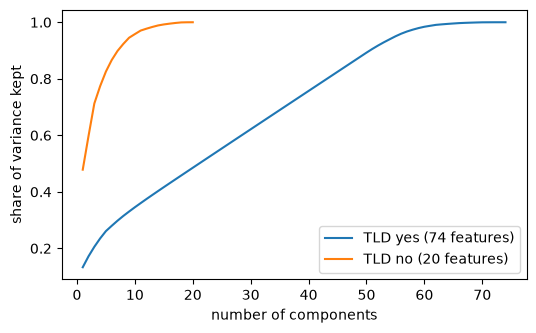

,TLD yes,TLD no
variance kept,,
0.80,44,5
0.95,55,10
0.99,62,15


In [3]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sample = train_full.sample(n=SAMPLE, random_state=0) if SAMPLE else train_full
X0 = feats["train"].loc[sample.index]

needed, fig = {}, plt.figure(figsize=(6, 3.5))
for tld, cols in [("yes", name_cols + tld_cols), ("no", name_cols)]:
    pca = PCA().fit(StandardScaler().fit_transform(X0[cols]))
    cum = np.cumsum(pca.explained_variance_ratio_)
    plt.plot(range(1, len(cum) + 1), cum, label=f"TLD {tld} ({len(cols)} features)")
    needed[f"TLD {tld}"] = {lvl: int(np.searchsorted(cum, lvl) + 1)
                            for lvl in PCA_LEVELS if lvl is not None}
plt.xlabel("number of components")
plt.ylabel("share of variance kept")
plt.legend()
plt.show()
pd.DataFrame(needed).rename_axis("variance kept")

## Train and test every level

For each PCA level: the 4 setups x every seed, in parallel (`run_seeds`), logged in MLflow
as `logreg_pca<level>`. Takes a while (the family-first fits are the slow ones).

In [4]:
from src.models.experiment import run_seeds, summarize

tables, summaries, gains = {}, {}, {}
for level in PCA_LEVELS:
    name = "all features" if level is None else f"PCA {level:.0%}"
    print("running:", name)
    t = run_seeds(feats, train_full, evaluate, X_eval_all, seeds=SEEDS, sample=SAMPLE,
                  pca=level, track=level is not None, eval_set=EVAL_SET,
                  run_name=f"logreg_pca{level}")
    tables[name] = t
    summaries[name], gains[name] = summarize(t)
print("done")

running: all features
running: PCA 80%
running: PCA 95%
running: PCA 99%
done


## Results: macro-F1 per setup

Mean (± std over the seeds) macro-F1 on validation, for every PCA level, with the number
of components used. Compare each PCA row with "all features".

In [5]:
rows = {}
for name, s in summaries.items():
    comps = tables[name]["n_components"].astype(float).groupby(["setup", "TLD"]).mean()
    for (setup, tld), r in s.iterrows():
        rows[name, f"{setup} TLD={tld}"] = (f"{r['mean']:.4f} ± {r['std']:.4f}"
                                           f"  ({comps[setup, tld]:.0f} comp.)")
pd.Series(rows).unstack().loc[list(summaries)]   # same order as PCA_LEVELS

,binary TLD=no,binary TLD=yes,family TLD=no,family TLD=yes
all features,0.9089 ± 0.0002 (20 comp.),0.9211 ± 0.0001 (74 comp.),0.9149 ± 0.0005 (20 comp.),0.9395 ± 0.0002 (74 comp.)
PCA 80%,0.8876 ± 0.0003 (5 comp.),0.9067 ± 0.0002 (44 comp.),0.8746 ± 0.0004 (5 comp.),0.9204 ± 0.0003 (44 comp.)
PCA 95%,0.8969 ± 0.0001 (10 comp.),0.9090 ± 0.0002 (55 comp.),0.8999 ± 0.0002 (10 comp.),0.9243 ± 0.0002 (55 comp.)
PCA 99%,0.9070 ± 0.0005 (15 comp.),0.9117 ± 0.0002 (62 comp.),0.9086 ± 0.0005 (15 comp.),0.9300 ± 0.0002 (62 comp.)


## Results: is family-first still better than binary?

Gain = family-first − binary macro-F1 (per seed, then averaged). "Better" follows the
proposal's rule: mean gain larger than its standard deviation.

In [6]:
pd.concat(gains, names=["features"]).round(4)

mean_gain  std_gain family_first_better
features     TLD                                        
all features yes  0.018393  0.000246                True
             no   0.006031  0.000335                True
PCA 80%      yes  0.013648  0.000268                True
             no  -0.012939   0.00008               False
PCA 95%      yes  0.015391   0.00037                True
             no   0.003014  0.000091                True
PCA 99%      yes  0.018389  0.000303                True
             no   0.001533  0.000165                True

**PCA result.** *(fill in after running: does PCA help, hurt, or change nothing? With how many components?)*